# 04 · Error analysis: which future partners does the model never see?

The ranker can only reorder the creators that candidate generation hands it. On validation, **about half of the
real new partnerships never reach the ranker**, so no ranking model, however good, can recover them. Before trying
yet another model, this notebook asks *why* they are missed.

> **Term — error analysis:** look at the cases a model gets wrong, by hand and with counts, group them by cause,
> and estimate how much fixing each cause could gain. It turns "how do I improve the model?" from guessing into a
> ranked list of experiments.

**Validation, not test.** Everything here uses the validation window (Oct–Dec 2018). The test window was used
once for the final number; studying its errors and then fixing them would quietly tune the model to the test set,
and the test result would no longer be an honest estimate.

The numbers come from `scripts/error_analysis.py` (~10 min), which rebuilds the candidates exactly as the final
model does and records, for every real new partnership, whether it was retrieved, by which source, and what the
creator and the brand looked like **at prediction time** (history only, no look-ahead).

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams.update({"figure.figsize": (9, 3.6), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "axes.axisbelow": True})
BLUE, ORANGE, INK = "#2a78d6", "#eb6834", "#52514e"
ROOT = Path.cwd().parent
summary = json.loads((ROOT / "results" / "error_analysis_val.json").read_text())
df = pd.read_parquet(ROOT / "artifacts" / "error_analysis_val.parquet")   # run scripts/error_analysis.py first
print(f"{summary['new_partnerships']:,} new partnerships for {summary['brands']:,} brands; "
      f"candidate recall {summary['candidate_recall']:.1%}, {summary['candidates_per_brand']:.0f} candidates per brand")

27,069 new partnerships for 6,508 brands; candidate recall 47.5%, 1116 candidates per brand


## 1. Where is the loss: retrieval or ranking?

Recall@50 is averaged per brand, so for a fair comparison candidate recall is averaged per brand too.

In [2]:
ranker = json.loads((ROOT / "results" / "ranker_val.json").read_text())["summary"]["ranker"]
cand_macro = df.groupby("brand").retrieved.mean().mean()
pd.Series({
    "real new partners that reach the ranker (candidate recall)": cand_macro,
    "real new partners in the ranker's top 50 (Recall@50)": ranker["recall@50"],
    "share of retrievable partners the ranker puts in its top 50": ranker["recall@50"] / cand_macro,
}).to_frame("validation, per-brand average").style.format("{:.1%}")

,"validation, per-brand average"
real new partners that reach the ranker (candidate recall),53.7%
real new partners in the ranker's top 50 (Recall@50),25.5%
share of retrievable partners the ranker puts in its top 50,47.5%


Roughly **half is lost at each stage**: candidate generation misses about half of the partners, and the ranker puts
about half of the remaining ones in its top 50. Both stages are worth work. This notebook is about the first one.

## 2. What each candidate source contributes

"Only this source" is the share of partners that no other source finds; it shows which sources actually earn their
place.

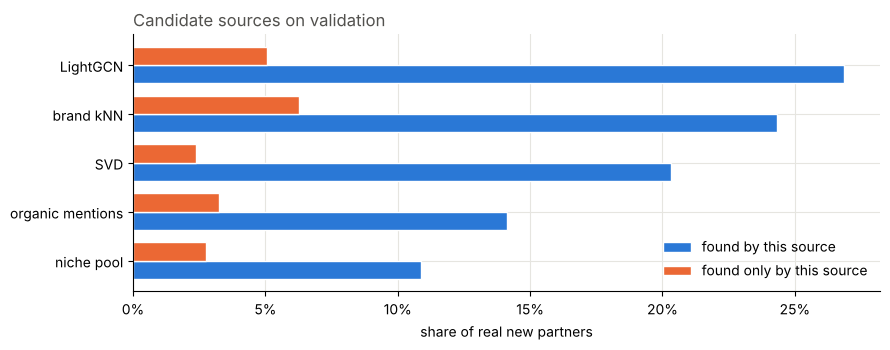

In [3]:
src = pd.DataFrame({"found by this source": summary["recall_by_source"],
                    "found only by this source": summary["only_this_source"]})
src.index = ["organic mentions", "brand kNN", "niche pool", "SVD", "LightGCN"]
ax = src.sort_values("found by this source").plot.barh(color=[BLUE, ORANGE], width=0.75, edgecolor="white")
ax.set_xlabel("share of real new partners"); ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_title("Candidate sources on validation", loc="left", color=INK); ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

LightGCN and brand kNN find the most partners, and every source finds some that no other one does, so none is
dead weight. Together they still reach only 47.5% (pair-weighted).

## 3. Hypotheses written down before looking

Writing guesses down first keeps the analysis honest; otherwise every finding looks "expected" afterwards.
Before looking, the guesses were: (a) creators with no history, (b) creators from another niche,
(c) small (micro) creators. Each is checked by comparing missed with retrieved partnerships.

In [4]:
def compare(feature: pd.Series, name: str) -> pd.DataFrame:
    t = pd.crosstab(feature, df.retrieved, normalize="columns").rename(columns={False: "missed", True: "retrieved"})
    return t.rename_axis(name)

first = (df.paid_brands == 0).map({True: "first paid collaboration ever", False: "had been paid before"})
display(compare(first, "(a) history").style.format("{:.1%}"))
display(compare(df.same_niche, "(b) creator niche vs brand niche").style.format("{:.1%}"))
display(compare(df.size_tier, "(c) creator size").style.format("{:.1%}"))

retrieved,missed,retrieved
(a) history,,
first paid collaboration ever,11.9%,5.1%
had been paid before,88.1%,94.9%


retrieved,missed,retrieved
(b) creator niche vs brand niche,,
different,57.4%,47.2%
same,16.5%,42.2%
unknown,26.1%,10.5%


retrieved,missed,retrieved
(c) creator size,,
nano <10k,23.6%,22.2%
micro 10–50k,41.8%,45.3%
mid 50–500k,30.2%,29.3%
macro 500k+,4.3%,3.2%


* **(a) mostly wrong.** Only about 12% of missed partners are doing their first paid collaboration. Most missed
  creators have been paid before.
* **(b) right, and big.** 57% of missed partners are in a different niche than the brand, against 47% of retrieved
  ones, and missed ones far more often have **no niche at all** (26% vs 11%).
* **(c) wrong.** Missed and retrieved partners have almost the same size mix.

## 4. Reading 50 misses by hand

Counts only answer the questions we thought of asking. Reading rows finds the ones we did not.
Topic numbers from NMF are arbitrary and change between fits, so they are named for *this* cutoff from their top
hashtags (the names in `niches.py` belong to the production fit).

In [5]:
for i, terms in summary["topics"].items():
    print(i, " ".join(terms))

0 fashion style model beauty outfit ootd hair smile makeup lifestyle
1 feedfeed foodie f52grams foodblogger eeeeeats instafood foodporn food buzzfeast foodphotography
2 makeup mua beauty makeupartist motd wakeupandmakeup beautyblogger makeupaddict makeupjunkie skincare
3 ootd fashionblogger styleblogger whatiwore outfitoftheday streetstyle fashionista wiw instastyle instafashion
4 momlife motherhood momblogger letthembelittle motherhoodunplugged momswithcameras childhoodunplugged candidchildhood ig_motherhood motherhoodthroughinstagram
5 fitness fitfam workout motivation fit fitspo gym fitnessmotivation health bodybuilding
6 travel travelblogger wanderlust travelgram beautifuldestinations instatravel passionpassport travelphotography sheisnotlost dametraveler
7 novababe nyfw ootd sp tbt plussizefashion nyc plussize linkinbio f21xme
8 soufeel soufeelgals soufeelnamenecklace soufeelstyle soufeellover dwforeveryone publi collaboration getanchored myrosefieldmoment
9 interiordesign homedec

In [6]:
NAMES = {0: "lifestyle", 1: "food", 2: "beauty", 3: "fashion", 4: "parenting", 5: "fitness", 6: "travel",
         7: "fast fashion & plus-size", 8: "jewelry campaign tags", 9: "home"}
df["brand_niche_name"] = df.brand_niche.map(NAMES)
df["creator_niche_name"] = df.creator_niche.map(NAMES)
df["brand_new_partners"] = df.brand.map(df.groupby("brand").size())
cols = ["brand", "brand_niche_name", "creator_niche_name", "followers", "brands_mentioned", "paid_brands_180d",
        "days_since_last_post", "brand_new_partners"]
pd.set_option("display.width", 200)
df[~df.retrieved].sample(50, random_state=0)[cols].reset_index(drop=True)

,brand,brand_niche_name,creator_niche_name,followers,brands_mentioned,paid_brands_180d,days_since_last_post,brand_new_partners
0,yoplaitusa,food,parenting,45588,55,18,10,3
1,mymuesli,food,lifestyle,10192,11,0,129,1
2,clarinsuk,beauty,fast fashion & plus-size,101819,14,5,0,3
3,gillette,lifestyle,NaN,888140,11,2,11,22
4,winc,parenting,beauty,11452,48,12,4,31
5,opaofgreece,NaN,fashion,3408,9,4,15,2
6,crabtreeandevelyn,parenting,fashion,26338,53,8,5,18
7,nespresso,food,food,19259,23,3,4,6
8,herobility,parenting,parenting,7104,2,1,3,11
9,aftershokz,fitness,food,6956,29,7,12,15


What stands out when reading the rows:

1. **Brand niches are often wrong for brands outside fashion and beauty.** A protein bar (lunabar), a private-jet
   company (netjets) and Walgreens are labelled *fast fashion*; wine brands are labelled *parenting* or *fast
   fashion*. A brand's niche is the average niche of the creators who mention it, and this dataset is dominated by
   fashion and mom creators, so general brands inherit their niche. The niche pool then searches the wrong niche.
2. **Many missed creators are experienced and active**: 10–20 paid collaborations in the last six months and a post
   in the last few days. They are not invisible; they are filed under the "wrong" niche.
3. **Giant brands**: Daniel Wellington starts 581 new partnerships in three months, H&M, Sephora and Nordstrom
   over 50. A fixed budget of ~1,100 candidates per brand cannot cover campaigns that size.
4. **Creators with no niche** use too few hashtags (fewer than 20 in their history) for the topic model, so they
   are excluded from the niche pool altogether.

## 5. Grouping the misses by cause

Each miss gets the first cause that applies, so the groups do not overlap.

In [7]:
def cause(r):
    if r.brand_new_partners > 50:
        return "giant brand (>50 new partners in 3 months)"
    if pd.isna(r.creator_niche):
        return "creator has no niche (too few hashtags)"
    if r.brands_mentioned <= 5:
        return "creator with little brand history (≤5 brands)"
    if r.same_niche == "different":
        return "creator with history, other niche than brand"
    return "creator with history, same niche (or brand niche unknown)"

df["cause"] = df.apply(cause, axis=1)
by_cause = df.groupby("cause").agg(partnerships=("retrieved", "size"), recall=("retrieved", "mean"),
                                   misses=("retrieved", lambda s: int((~s).sum())))
by_cause["share of all misses"] = by_cause.misses / by_cause.misses.sum()
by_cause = by_cause.sort_values("misses", ascending=False)
by_cause.style.format({"recall": "{:.1%}", "share of all misses": "{:.1%}", "partnerships": "{:,}", "misses": "{:,}"})

,partnerships,recall,misses,share of all misses
cause,,,,
"creator with history, other niche than brand","11,823",44.8%,"6,526",45.9%
creator has no niche (too few hashtags),"3,882",25.2%,"2,903",20.4%
"creator with history, same niche (or brand niche unknown)","7,252",71.0%,"2,104",14.8%
giant brand (>50 new partners in 3 months),"3,268",37.9%,"2,029",14.3%
creator with little brand history (≤5 brands),844,23.8%,643,4.5%


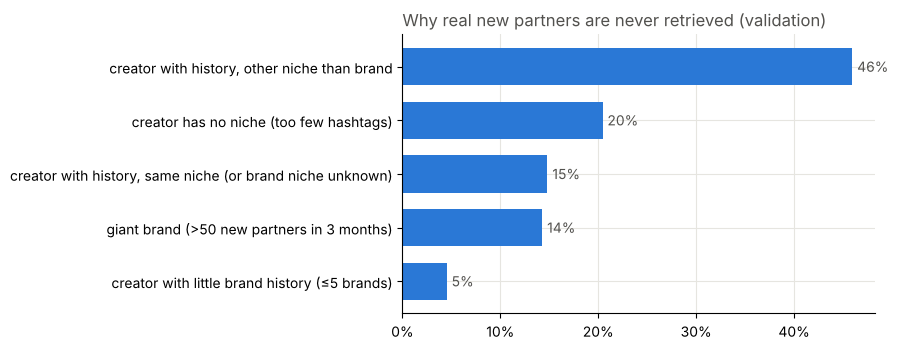

In [8]:
ax = by_cause["share of all misses"].sort_values().plot.barh(color=BLUE, width=0.7)
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}"); ax.set_ylabel("")
ax.set_title("Why real new partners are never retrieved (validation)", loc="left", color=INK)
for i, v in enumerate(by_cause["share of all misses"].sort_values()):
    ax.text(v + 0.005, i, f"{v:.0%}", va="center", color=INK)
plt.tight_layout(); plt.show()

**Creators from another niche than the brand are the largest group (~46% of misses)**, followed by creators
without a niche (~20%) and giant brands (~14%). Creators with almost no brand history, the original guess, are
under 5%.

> **Careful: a big group is not a big cause.** Look at the `recall` column. Partnerships with a creator from
> another niche are still found 43% of the time, close to the 47.5% average: cross-niche partnerships are simply
> common (47% of the *retrieved* ones are cross-niche too). An attribute explains misses only if it is much more
> frequent among misses than among hits. By that test the strongest signals are a creator **without a niche**
> (found 25%), **little brand history** (24%) and **giant brands** (38%), against 71% for same-niche pairs.
> The follow-up below learned this the hard way.

## 6. Ceiling analysis: what would a fix buy, and at what cost?

Before building a fix, estimate its best case. The script adds three cheap "what if" sources and counts how many
missed partners they would catch. Each one adds candidates, which costs ranking time and makes the ranker's job
harder, so the gain is shown next to its cost.

In [9]:
cur = summary["candidate_recall"]
what_if = pd.DataFrame({
    "candidate recall": {"current": cur, **summary["what_if_recall"]},
    "extra candidates per brand (at most)": {"current": 0, "pop300": 300, "pop1000": 1000, "niche_top2": 300},
})
what_if["gain (points)"] = (what_if["candidate recall"] - cur) * 100
what_if.index = ["current model", "+ 300 most active paid creators", "+ 1,000 most active paid creators",
                 "niche pool from the brand's top-2 niches"]
what_if.style.format({"candidate recall": "{:.1%}", "gain (points)": "{:+.1f}"})

,candidate recall,extra candidates per brand (at most),gain (points)
current model,47.5%,0,+0.0
+ 300 most active paid creators,48.8%,300,+1.2
"+ 1,000 most active paid creators",52.5%,1000,+5.0
niche pool from the brand's top-2 niches,49.9%,300,+2.3


The gains are **smaller than the size of the groups suggests**, which is itself a finding:

* Using the brand's **two strongest niches** gains +2.3 points for at most 300 extra candidates: the best gain per
  candidate, and it targets the largest group directly.
* Adding the most active creators for every brand needs **1,000 extra candidates (nearly double)** to gain
  +5 points. Missed creators are active, but not *the* most active ones, so popularity alone is an expensive fix.
* Neither helps creators without a niche or most of the giant-brand misses: those need their own fixes.

## Conclusions and next experiments

The earlier notebook said half of the partners are missed because "the decisive factors are not in public posts".
Error analysis shows that is only part of the story: many missed creators are visible and active, and niche
labels are noisy for brands outside fashion and beauty. Ranked by expected gain per cost:

1. **Better brand niches.** Use the brand's niche *mix* (top-2 niches) in the niche pool (+2.3 points measured),
   and for brands mentioned by few creators fall back to a broader "general" pool instead of a noisy argmax.
2. **A niche for creators with few hashtags.** Infer it from the brands they mention (brands already have niches),
   so they can enter the niche pool. 20% of misses; cheap to try.
3. **Candidate budget proportional to the brand.** Brands that historically start many partnerships get more
   candidates (e.g. scaled by past paid creators), instead of the same ~1,100 for everyone.
4. **Then measure end to end.** Higher candidate recall only matters if the ranker turns it into a higher
   Recall@50, so every change is judged by validation Recall@50, and the test window is touched once at the end.


## Follow-up: we tried fix 1 (experiment R9)

Two observations from the data shaped the fix:

* **Creators mix niches.** 39% of bios that name a niche name two or more ("mom of 3 | fashion lover").
* **Brands hire outside their niche.** Only 27–43% of a brand's new partners are in the brand's own niche; food
  brands, for example, hire many parenting creators.

So creators got a niche *mix* (from hashtags, and from profile bios for creators who use few hashtags; only
keyword counts are extracted from bios, never the text), and every brand an *affinity*: the niche mix of the
creators it paid before, smoothed towards its category when it has little history. A new candidate source fills
each brand's slots from niches in proportion to that affinity, and the ranker gets the match as a feature.

In [10]:
aff = json.loads((ROOT / "results" / "affinity_val.json").read_text())
display(pd.DataFrame({k: v for k, v in aff.items() if k != "coverage"}).T
        .style.format({"candidate_recall": "{:.1%}", "candidates_per_brand": "{:.0f}"}))
print({k: f"{v:.0%}" for k, v in aff["coverage"].items()})
r7 = json.loads((ROOT / "results" / "ranker_val.json").read_text())["summary"]["ranker"]
r9 = json.loads((ROOT / "results" / "ranker_val_affinity-add.json").read_text())["summary"]["ranker"]
pd.DataFrame({"R7 (final model)": r7, "R9 (+ affinity)": r9}).T.drop(columns="top10_median_followers").round(4)

,candidate_recall,candidates_per_brand
current,47.5%,1116
+ affinity (hashtags),48.5%,1209
+ affinity (hashtags + bio),48.6%,1203
affinity instead of niche pool,46.3%,1022


{'new partners whose creator has a niche mix (hashtags)': '52%', 'new partners whose creator has a niche mix (hashtags + bio)': '80%'}


,recall@10,recall@50,recall@100,ndcg@50
R7 (final model),0.1447,0.2553,0.3212,0.1348
R9 (+ affinity),0.1444,0.2589,0.3224,0.1343


**Result: no real gain.** Candidate recall rises by about one point, but Recall@50 stays at R7's level
(differences below ~0.005 are noise in this setup). Bios raise the share of new partners whose creator has a known
niche from 52% to 80%, yet they barely move candidate recall: the pool takes the most active creators, who use
hashtags anyway.

R9 is logged in `EXPERIMENTS.md` and not adopted; the code stays behind `train_ranker.py --affinity`.

## Why niches cannot fix it

Two numbers explain the weak result. They need the data, so this cell recomputes them (~1 min).

In [11]:
import sys
sys.path.insert(0, str(ROOT / "src"))
from mlrec import affinity as A
from mlrec.config import DATA_DIR
from mlrec.data import load_posts, to_interactions
from mlrec.split import make_task

posts, _, brands = load_posts()
task = make_task(to_interactions(posts, brands), *summary["window"])
mix = A.creator_mix(posts[posts.ts < task.cutoff], A.load_bio_niches(DATA_DIR))
aff, ranked = A.brand_affinity(task, mix), A.ranked_creators(task, mix)

missed = df.loc[~df.retrieved, ["brand", "creator_id"]]
hires = aff.stack().rename("w").reset_index().set_axis(["brand", "group", "w"], axis=1).query("w >= 0.15")
pos_in_list = (missed.merge(hires, on="brand").merge(ranked, on=["group", "creator_id"], how="left")
               .groupby(["brand", "creator_id"]).pos.min().reindex(pd.MultiIndex.from_frame(missed)))
listed = pos_in_list.dropna()
print("experienced creators per niche:", ranked.groupby("group").size().to_dict())
print(f"missed partners not on any list of a niche the brand hires from: {pos_in_list.isna().mean():.0%}")
print(f"for the others, median position in that niche list: {listed.median():.0f}; "
      f"within the first 300: {(listed < 300).mean():.0%}, within 1,000: {(listed < 1000).mean():.0%}")

experienced creators per niche: {'beauty': 3142, 'family': 3056, 'fashion': 6865, 'fitness': 1712, 'food': 2501, 'home': 1355, 'travel': 2744}
missed partners not on any list of a niche the brand hires from: 52%
for the others, median position in that niche list: 1282; within the first 300: 13%, within 1,000: 41%


* **A niche says "which neighbourhood", not "which house".** Each niche holds 1,300–6,900 experienced creators,
  and a brand gets ~300 niche slots. Missed partners who are on a relevant niche list sit around position 1,300,
  so only about one in eight would fit into 300 slots.
* **About half of the missed partners are on no niche list at all:** no paid collaboration in the last six months,
  or no niche signal. A niche-based source cannot reach them however it is tuned.

Choosing the right house inside a neighbourhood means ranking creators by similarity to the brand's past partners,
which is exactly what kNN and LightGCN already do.

## Ablation: what if niches are removed completely? (experiment A2)

Before running it, the prediction was: candidate recall −2 to −3 points (the niche pool alone finds 2.7% of
partners), Recall@50 down by 0.003–0.008.

In [12]:
a2 = json.loads((ROOT / "results" / "ranker_val_no-niche.json").read_text())["summary"]["ranker"]
pd.DataFrame({"R7 (final model)": r7, "R9 (+ affinity)": r9, "A2 (no niche pool, no niche features)": a2}).T     .drop(columns="top10_median_followers").round(4)

,recall@10,recall@50,recall@100,ndcg@50
R7 (final model),0.1447,0.2553,0.3212,0.1348
R9 (+ affinity),0.1444,0.2589,0.3224,0.1343
"A2 (no niche pool, no niche features)",0.1450,0.2540,0.3187,0.1335


Without niches candidate recall drops from 47.5% to 44.8% with 18% fewer candidates (913 instead of 1,116 per
brand), but **Recall@50 stays within noise of R7**. The partners only the niche pool found were ones the ranker
rarely put in its top 50 anyway, and the rest of the niche information is already carried by kNN and LightGCN.

**Decision:** R7 stays the final model. It was evaluated once on the test window, and swapping in a model chosen
afterwards would make that test number less honest. The lesson goes into the next version: niches are useful for
**people** (filters and explanations in the app), but add almost nothing to **ranking**; a simpler model without
them would rank about as well with fewer candidates.